# Notebook B: chia dữ liệu, mô hình và câu hỏi thứ ba

**Đề tài:** Mô hình thay thế cho trang trại điện sóng cần bao nhiêu bố trí mô phỏng và có chuyển được sang vùng biển và quy mô khác hay không

**Sinh viên B** chạy sau khi Notebook A đã tạo file parquet, `sql/queries.sql` và `manifest.json`. Notebook này không cần kernel của Notebook A.

## Kiểm tra bàn giao

- **Làm gì:** đọc manifest và so mã băm của file parquet.
- **Vì sao:** bảo đảm hai notebook dùng đúng cùng một dữ liệu.
- **Kiểm tra:** ô in `handover ok`.

In [1]:
# run once per machine, then comment out
%pip install pandas numpy duckdb pyarrow scikit-learn lightgbm xgboost matplotlib scipy
import os, json, hashlib, numpy as np, pandas as pd, warnings
warnings.filterwarnings('ignore')
m = json.load(open('data/processed/manifest.json'))
assert hashlib.md5(open(m['file'], 'rb').read()).hexdigest() == m['md5'], 'parquet differs from the manifest, rerun Notebook A'
os.makedirs('report', exist_ok=True); print('handover ok', m['rows'], 'rows')

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


handover ok 19723 rows


## Bước 4. Bảng đặc trưng và chia dữ liệu

- **Làm gì:** chạy lại `sql/queries.sql`, lấy bảng `feat`, chia tập huấn luyện và kiểm thử theo giao thức của đề tài.
- **Vì sao:** cách chia quyết định con số có đáng tin hay không; dòng `assert` là phép kiểm tra rò rỉ.
- **Kiểm tra:** ghi số dòng hai tập và số đặc trưng vào bảng mô tả thực nghiệm.

In [2]:
# Step 4: split of the Perth 49-converter layouts by groups of identical geometry features
# (layouts with identical features always stay on the same side, so no near-copy of a test layout is in training)
import duckdb
from sklearn.model_selection import train_test_split, GroupShuffleSplit
con = duckdb.connect(); con.execute(open('sql/queries.sql').read())
feat = con.execute("SELECT * FROM feat ORDER BY row_id").df()
GEO = ['nn_mean', 'nn_min', 'nn_std', 'pair_mean', 'share_closer_100m', 'x_std', 'y_std', 'x_range', 'y_range', 'pairs_within_200m', 'pairs_within_400m']
X_cols = GEO; TARGET = 'qW'; HOME = 'Perth_49'            # the q-factor has no unit, so it can be compared between sites and farm sizes
feat['grp'] = feat.groupby(GEO + ['site', 'n_wec']).ngroup()          # same features, site and farm size = same group
home = feat[feat.file == HOME].reset_index(drop=True)
idx_tr, idx_te = next(GroupShuffleSplit(1, test_size=0.2, random_state=0).split(home, groups=home.grp))
train, test = home.iloc[idx_tr], home.iloc[idx_te].copy()
train_rnd, test_rnd = train_test_split(home, test_size=0.2, random_state=0)   # old random split, kept only to measure how much it overestimates (Step 6c)
test['ref'] = train[TARGET].mean(); NAIVE = 'ref'
X_tr, y_tr, X_te, y_te = train[X_cols], train[TARGET], test[X_cols], test[TARGET]
assert set(train.row_id).isdisjoint(test.row_id)         # leakage check: no shared layout
assert set(train.grp).isdisjoint(test.grp)               # leakage check: no shared group of identical features
print(len(train), len(test), len(X_cols), 'features', 'files:', feat.file.value_counts().to_dict())

8777 2159 11 features files: {'Perth_49': 10936, 'Sydney_49': 4816, 'Perth_100': 2737, 'Sydney_100': 1234}


## Bước 4b. Hiểu tập huấn luyện và tập kiểm thử

Ba ô dưới đây kiểm tra hai tập có giống nhau không và đặc trưng nào mạnh nhất, trước khi huấn luyện bất kỳ mô hình nào.

### 4b.1 Mục tiêu ở hai tập

- **Làm gì:** so phân phối của mục tiêu giữa tập huấn luyện và tập kiểm thử.
- **Vì sao:** hai phân phối lệch nhau giải thích vì sao mô hình cây ngoại suy kém.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

train rows 8777 test rows 2159 features 11


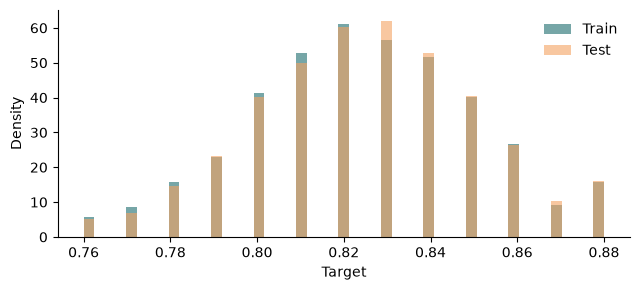

          train      test
count  8777.000  2159.000
mean      0.824     0.825
std       0.027     0.026
min       0.720     0.720
25%       0.810     0.810
50%       0.820     0.830
75%       0.840     0.840
max       0.880     0.880


In [3]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

import matplotlib.pyplot as plt
def nice(v, label):                                     # readable numbers on the bars
    v = np.asarray(v, dtype=float); m = np.nanmax(np.abs(v))
    return (v / 1e6, label + ' (million)', '{:.2f}') if m >= 1e6 else (v / 1e3, label + ' (thousand)', '{:.1f}') if m >= 1e4 else (v, label, '{:.2f}' if m < 100 else '{:.0f}')
ytr, yte = pd.Series(np.asarray(y_tr, dtype=float)), pd.Series(np.asarray(y_te, dtype=float)); BINARY = ytr.nunique() <= 2
print('train rows', len(ytr), 'test rows', len(yte), 'features', X_tr.shape[1])
if BINARY: print('positive share: train %.3f, test %.3f' % (ytr.mean(), yte.mean()))
else:
    fig, ax = plt.subplots(figsize=(6.5, 3)); lo, hi = min(ytr.quantile(.01), yte.quantile(.01)), max(ytr.quantile(.99), yte.quantile(.99)); bins = np.linspace(lo, hi, 50)
    ax.hist(ytr.clip(lo, hi), bins=bins, density=True, alpha=.6, color='#1B6B6D', label='Train'); ax.hist(yte.clip(lo, hi), bins=bins, density=True, alpha=.6, color='#F4A261', label='Test')
    ax.legend(frameon=False); ax.set_xlabel('Target'); ax.set_ylabel('Density'); ax.spines[['top', 'right']].set_visible(False); fig.tight_layout(); fig.savefig('report/fig_split_target.png', dpi=200); plt.show()
    print(pd.DataFrame({'train': ytr.describe(), 'test': yte.describe()}).round(3))

### 4b.2 Đặc trưng lệch giữa hai tập

- **Làm gì:** độ lệch trung bình chuẩn hoá của từng đặc trưng giữa hai tập.
- **Kiểm tra:** đặc trưng lệch trên 0,5 độ lệch chuẩn là nguồn rủi ro, nêu trong mục Limitations.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [4]:
A_, B_ = X_tr.astype(float), X_te.astype(float); sd = A_.std().replace(0, np.nan)
shift = ((B_.mean() - A_.mean()) / sd).abs().sort_values(ascending=False).rename('abs_standardised_mean_difference')
shift.to_csv('report/table_split_shift.csv'); display(shift.head(10).round(3).to_frame())
print('features whose test mean lies more than 0.5 training standard deviations away:', int((shift > 0.5).sum()), 'of', len(shift))

,abs_standardised_mean_difference
nn_mean,0.049
nn_std,0.034
share_closer_100m,0.032
y_std,0.025
nn_min,0.024
pairs_within_200m,0.023
x_range,0.023
pair_mean,0.012
pairs_within_400m,0.011
y_range,0.007


features whose test mean lies more than 0.5 training standard deviations away: 0 of 11


### 4b.3 Sức mạnh của từng đặc trưng

- **Làm gì:** tương quan hạng giữa từng đặc trưng và mục tiêu trên tập huấn luyện.
- **Vì sao:** nếu một đặc trưng đã gần đủ, mô hình phức tạp sẽ không hơn nhiều, và đó là thông tin để chọn câu hỏi.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [5]:
sig = A_.sample(min(len(A_), 20_000), random_state=0); ys = pd.Series(np.asarray(y_tr, dtype=float), index=X_tr.index).loc[sig.index]
strength = sig.corrwith(ys, method='spearman').abs().sort_values(ascending=False).rename('abs_rank_correlation_with_target')
strength.to_csv('report/table_feature_strength.csv'); display(strength.head(10).round(3).to_frame())
print('strongest single feature:', strength.index[0], round(float(strength.iloc[0]), 3), '-> a model must beat what this feature already gives')

,abs_rank_correlation_with_target
nn_mean,0.550
share_closer_100m,0.533
nn_std,0.521
pairs_within_200m,0.322
nn_min,0.274
y_range,0.224
x_range,0.202
pairs_within_400m,0.113
x_std,0.055
pair_mean,0.020


strongest single feature: nn_mean 0.55 -> a model must beat what this feature already gives


## Bước 6a. So sánh mô hình (RQ2)

- **Làm gì:** huấn luyện mười mô hình với năm seed trên cùng cách chia.
- **Vì sao:** so nhiều họ mô hình để kết luận không phụ thuộc một kiểu mô hình; năm seed cho độ lệch chuẩn.
- **Kiểm tra:** chênh lệch nhỏ hơn độ lệch chuẩn thì chưa được kết luận mô hình nào hơn. Bảng lưu ở `report/table_rq2.csv`.

In [6]:
# Step 6a: one reference and ten regressors from four families, five seeds, same random split of layouts
import numpy as np, pandas as pd, time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error as MAE, mean_squared_error as MSE, r2_score
sc = lambda m: make_pipeline(StandardScaler(), m)       # scaling for linear, distance and neural models
models = {
    'Ridge':          lambda s: sc(Ridge(alpha=1.0)),
    'Elastic Net':    lambda s: sc(ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=5000, random_state=s)),
    'k-NN':           lambda s: sc(KNeighborsRegressor(n_neighbors=15)),
    'Decision Tree':  lambda s: DecisionTreeRegressor(max_depth=12, min_samples_leaf=10, random_state=s),
    'Random Forest':  lambda s: RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s),
    'Extra Trees':    lambda s: ExtraTreesRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s),
    'HistGB':         lambda s: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=s),
    'LightGBM':       lambda s: LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=31, subsample=0.8,
                                              subsample_freq=1, colsample_bytree=0.8, random_state=s, verbose=-1),
    'XGBoost':        lambda s: XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=6, subsample=0.8,
                                             colsample_bytree=0.8, tree_method='hist', random_state=s),
    'Small MLP':      lambda s: sc(MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True,
                                                random_state=s)),
}
naive = test[NAIVE]                                     # reference: the mean q-factor of the training layouts
rows, fitted = [['Train mean', MAE(y_te, naive), 0, MSE(y_te, naive) ** 0.5, r2_score(y_te, naive), 0]], {}
for name, make in models.items():
    maes, rmses, r2s, secs = [], [], [], []
    for seed in range(5):
        m = make(seed); t0 = time.perf_counter(); m.fit(X_tr, y_tr); secs.append(time.perf_counter() - t0)
        p = m.predict(X_te); maes.append(MAE(y_te, p)); rmses.append(MSE(y_te, p) ** 0.5); r2s.append(r2_score(y_te, p))
    fitted[name] = m                                    # keep the last fitted model of each family for Step 6b
    rows.append([name, np.mean(maes), np.std(maes), np.mean(rmses), np.mean(r2s), np.mean(secs)])
res = pd.DataFrame(rows, columns=['model', 'MAE', 'sd', 'RMSE', 'R2', 'train_s'])
res.to_csv('report/table_rq2.csv', index=False); print(res.round(4))

            model     MAE      sd    RMSE      R2  train_s
0      Train mean  0.0212  0.0000  0.0263 -0.0012   0.0000
1           Ridge  0.0123  0.0000  0.0161  0.6249   0.0062
2     Elastic Net  0.0173  0.0000  0.0221  0.2945   0.0053
3            k-NN  0.0107  0.0000  0.0147  0.6873   0.0187
4   Decision Tree  0.0121  0.0000  0.0166  0.6010   0.0598
5   Random Forest  0.0102  0.0000  0.0142  0.7078   1.1780
6     Extra Trees  0.0102  0.0000  0.0140  0.7154   0.5641
7          HistGB  0.0103  0.0000  0.0141  0.7148   0.8387
8        LightGBM  0.0103  0.0000  0.0140  0.7155   0.4518
9         XGBoost  0.0102  0.0000  0.0140  0.7178   0.6691
10      Small MLP  0.0118  0.0006  0.0162  0.6179   3.3516


### Hình RQ2

- **Làm gì:** vẽ kết quả các mô hình, tô màu nhấn mô hình tốt nhất.
- **Kiểm tra:** số trên cột khớp với `report/table_rq2.csv`.

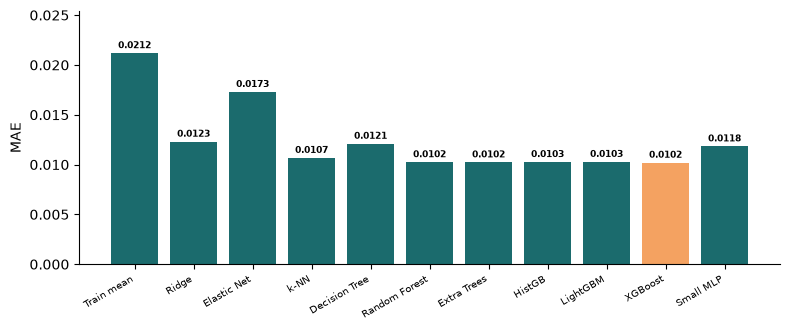

In [7]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(8, 3.4))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=6.5 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

bar_chart(res.model, res.iloc[:, 1], res.columns[1], 'report/fig_rq2_models.png', highlight=int(res.iloc[:, 1].idxmin()), fmt='{:.4f}')

In [8]:
# Step 6b (1): RQ3, how many simulated layouts are enough? learning curve with training time
SIZES = [s for s in [250, 500, 1000, 2000, 4000, 8000, 16000] if s < len(train)] + [len(train)]   # finer grid: the de-duplicated Perth 49 file is smaller; rows = []
for name, make in models.items():
    for n in SIZES:
        for seed in range(2):
            sub = train.sample(n, random_state=seed) if n < len(train) else train
            t0 = time.perf_counter(); p = make(seed).fit(sub[X_cols], sub[TARGET]).predict(X_te); rows.append([name, n, seed, r2_score(y_te, p), MAE(y_te, p), time.perf_counter() - t0])
lc = pd.DataFrame(rows, columns=['model', 'n', 'seed', 'R2', 'MAE', 'seconds']).groupby(['model', 'n'])[['R2', 'MAE', 'seconds']].mean().reset_index()
lc.to_csv('report/table_rq3_learning_curve.csv', index=False)
sat = lc.sort_values('n').groupby('model').apply(lambda g: pd.Series({'R2_at_max': g.R2.iloc[-1], 'layouts_to_within_0.01_R2': g.n[g.R2 >= g.R2.iloc[-1] - 0.01].iloc[0]}))
sat.to_csv('report/table_rq3_saturation.csv'); print(sat.round(3))

               R2_at_max  layouts_to_within_0.01_R2
model                                              
Decision Tree      0.601                   8000.000
Elastic Net        0.295                    250.000
Extra Trees        0.716                   8000.000
HistGB             0.715                   8000.000
LightGBM           0.716                   8000.000
Random Forest      0.708                   8000.000
Ridge              0.625                   2000.000
Small MLP          0.649                   8777.000
Train mean         0.026                      0.021
XGBoost            0.716                   8000.000
k-NN               0.687                   8000.000


## Cổng khả thi: có nên xoay câu hỏi không

- **Làm gì:** so mô hình tốt nhất với mốc đơn giản và in ra một trong ba kết luận.
- **Vì sao:** nếu mô hình không hơn mốc hoặc bài toán quá dễ, nhóm xoay câu hỏi ngay ở đây thay vì cố chỉnh mô hình. Xoay câu hỏi nghĩa là đổi điều được hỏi cho khớp với điều dữ liệu trả lời được, không phải chọn lại số liệu cho đẹp.

**Các hướng xoay của đề tài này:**

1. Nếu R2 trong một file đã cao với ít bố trí: trục chính là số mô phỏng tiết kiệm được.
2. Nếu chuyển giữa file kém: giữ làm kết quả, thêm phép sửa mức bằng vài chục bố trí của file đích.
3. Nếu toạ độ thô ngang đặc trưng hình học: bỏ phần so đặc trưng, tập trung vào đường cong học.

**Quyết định của nhóm (giữ câu hỏi hay xoay theo hướng nào, vì sao):** ...

In [9]:
ref, best = res.iloc[0], res.iloc[1:].sort_values('MAE').iloc[0]; skill = 100 * (1 - best.MAE / ref.MAE)
print('reference %s: MAE %.4f | best model %s: MAE %.4f | improvement %.1f%%' % (ref.model, ref.MAE, best.model, best.MAE, skill))
verdict = 'GOOD: the model clearly beats the reference, keep RQ2 as planned' if skill >= 10 else 'SMALL: report the reference as a strong baseline and move the contribution to RQ3' if skill >= 2 else 'NONE: the reference wins, pivot the question (see the options above) and report this result honestly'
print(verdict); pd.Series({'reference_MAE': ref.MAE, 'best_model': best.model, 'best_MAE': best.MAE, 'improvement_pct': skill, 'verdict': verdict}).to_csv('report/table_feasibility_gate.csv')

reference Train mean: MAE 0.0212 | best model XGBoost: MAE 0.0102 | improvement 51.9%
GOOD: the model clearly beats the reference, keep RQ2 as planned


## Bước 6b. Câu hỏi thứ ba (RQ3)

- **Làm gì:** Cách chia là theo nhóm có đặc trưng hình học giống hệt nhau (GroupShuffleSplit), không chia ngẫu nhiên theo dòng. huấn luyện lại mười mô hình với năm cỡ tập huấn luyện và trong từng file đích.
- **Vì sao:** đây là đóng góp chính của bài; mỗi bảng `report/table_rq3_*.csv` ứng với một ý trong mục Results.
- **Kiểm tra:** đọc từng bảng in ra và viết một câu kết luận có số cho mỗi bảng. Nếu kết quả trái dự kiến trong đề cương thì báo đúng như vậy và tìm nguyên nhân, không chỉnh code cho ra kết quả mong muốn.

In [10]:
# (2) transfer: mô hình huấn luyện trên file nhà, hiệu chỉnh bằng k layout của file đích
from sklearn.model_selection import GroupShuffleSplit
KS, NREP = [20, 50, 100], 10                      # k = số layout của file đích dùng để hiệu chỉnh, lặp 10 lần lấy mẫu
if 'grp' not in feat.columns: feat['grp'] = feat.groupby(GEO + ['site', 'n_wec']).ngroup()   # layout trùng đặc trưng = cùng nhóm
rows = []
for target in [f for f in sorted(feat.file.unique()) if f != HOME]:
    T = feat[feat.file == target].reset_index(drop=True)
    i, j = next(GroupShuffleSplit(1, test_size=0.2, random_state=0).split(T, groups=T.grp)); a, b = T.iloc[i], T.iloc[j]
    for name, make in models.items():
        inside = r2_score(b[TARGET], make(0).fit(a[X_cols], a[TARGET]).predict(b[X_cols]))      # huấn luyện ngay trong file đích
        p = fitted[name].predict(b[X_cols]); raw_r2 = r2_score(b[TARGET], p); corr = float(np.corrcoef(b[TARGET], p)[0, 1])
        for k in KS:
            lvl, lin = [], []
            for s in range(NREP):
                sub = a.sample(k, random_state=s); ps = fitted[name].predict(sub[X_cols])
                lvl.append(r2_score(b[TARGET], p - ps.mean() + sub[TARGET].mean()))              # chỉ sửa mức
                slope, icpt = np.polyfit(ps, sub[TARGET], 1); lin.append(r2_score(b[TARGET], slope * p + icpt))   # sửa mức và độ dốc
            rows.append([target, name, k, inside, raw_r2, np.mean(lvl), np.mean(lin), np.std(lin), corr])
tr = pd.DataFrame(rows, columns=['target_file', 'model', 'k', 'R2_trained_inside', 'R2_transferred', 'R2_level_corrected', 'R2_linear_corrected', 'sd_linear_corrected', 'correlation_transferred'])
tr.to_csv('report/table_rq3_transfer.csv', index=False)
print(tr.groupby(['target_file', 'k'])[['R2_trained_inside', 'R2_transferred', 'R2_level_corrected', 'R2_linear_corrected']].mean().round(3))

                 R2_trained_inside  R2_transferred  R2_level_corrected  \
target_file k                                                            
Perth_100   20               0.493       -2925.536             -45.203   
            50               0.493       -2925.536             -44.633   
            100              0.493       -2925.536             -43.830   
Sydney_100  20               0.056      -10380.131            -236.645   
            50               0.056      -10380.131            -233.852   
            100              0.056      -10380.131            -230.139   
Sydney_49   20               0.807         -25.180              -2.822   
            50               0.807         -25.180              -2.702   
            100              0.807         -25.180              -2.651   

                 R2_linear_corrected  
target_file k                         
Perth_100   20                 0.170  
            50                 0.206  
            100              

## Bước 6c. Kiểm tra bổ sung và bảng tham số

- **Làm gì:** chạy phép kiểm tra bổ sung của đề tài và lưu tham số mô hình.
- **Vì sao:** bảng này đi vào phần thảo luận và phụ lục của bài.
- **Kiểm tra:** `report/params_best.json` tồn tại.

In [11]:
# Step 6c: raw coordinates against geometry features on the home file, group split against random split, and parameters
best = res.iloc[1:].sort_values('MAE').model.iloc[0]
raw = pd.read_parquet('data/processed/wave_raw49.parquet'); raw = raw[raw.site == HOME.split('_')[0]].reset_index(drop=True)
assert len(raw) == len(home), 'raw coordinate table and feature table differ'
RAW = [c for c in raw.columns if c not in ('site', 'qW')]; a, b = raw.iloc[idx_tr], raw.iloc[idx_te]      # same group split as the geometry features
cmp = pd.DataFrame([['geometry features', len(GEO), r2_score(y_te, fitted[best].predict(X_te))],
                    ['raw coordinates', len(RAW), r2_score(b.qW, models[best](0).fit(a[RAW], a.qW).predict(b[RAW]))]], columns=['inputs', 'n_features', 'R2'])
cmp.to_csv('report/table_rq3_inputs.csv', index=False); print(best); print(cmp.round(3))
m_rnd = models[best](0).fit(train_rnd[X_cols], train_rnd[TARGET])                    # same model, old random split of the same file
rep_ = pd.Series({'test_layouts': len(test), 'repeated_in_test': int(test.repeated.sum()),
                  'R2_random_split': r2_score(test_rnd[TARGET], m_rnd.predict(test_rnd[X_cols])),
                  'R2_group_split': r2_score(y_te, fitted[best].predict(X_te))})
rep_.rename('value').to_csv('report/table_rq3_repeated_layouts.csv'); print(rep_.round(4))
import json
json.dump({'best': best, 'home_file': HOME, 'params': {k: str(v) for k, v in models[best](0).get_params().items()}}, open('report/params_best.json', 'w'), indent=2)

XGBoost
              inputs  n_features     R2
0  geometry features          11  0.719
1    raw coordinates          98  0.898
test_layouts        2159.0000
repeated_in_test     115.0000
R2_random_split        0.7130
R2_group_split         0.7192
dtype: float64


### Hình RQ3

- **Làm gì:** vẽ hai hình RQ3 từ các bảng `report/table_rq3_*.csv` bằng hàm `bar_chart` ở trên, theo mẫu Hình 4 và Hình 5 của đề cương.
- **Kiểm tra:** mỗi hình một ý, chữ tiếng Anh, số in đậm trên cột.

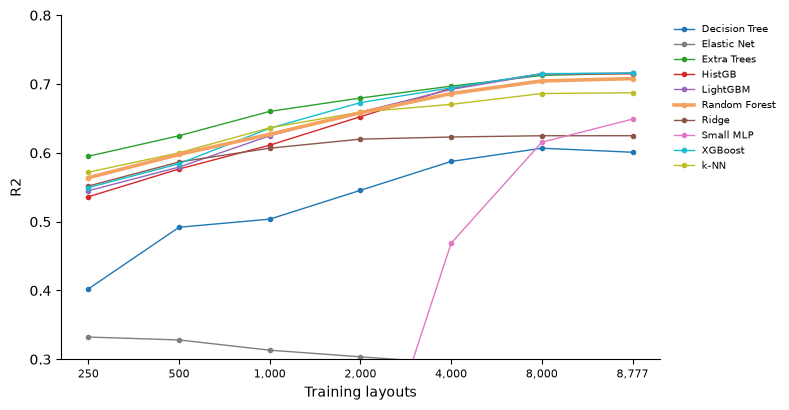

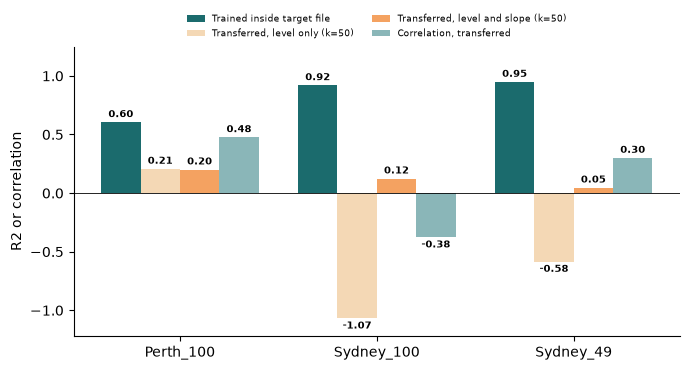

In [17]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
OUT = 'report'

# Hình 4: đường cong học
lc = pd.read_csv(f'{OUT}/table_rq3_learning_curve.csv')
lc = lc[lc.n >= 250]                         # <-- bỏ các n nhỏ (nhãn "0") và vùng R2 quá thấp
lc = lc[lc.model != 'Train mean']            # <-- bỏ đường nền R2 ≈ 0
fig, ax = plt.subplots(figsize=(8, 4.2))
pal = ['#1f77b4','#7f7f7f','#2ca02c','#d62728','#9467bd','#8c564b','#e377c2','#17becf','#bcbd22']
others = [m for m in sorted(lc.model.unique()) if m != 'Random Forest']
col = {m: pal[i % len(pal)] for i, m in enumerate(others)}; col['Random Forest'] = '#F4A261'
ns = sorted(lc.n.unique()); pos = {n: i for i, n in enumerate(ns)}
for name, g in lc.groupby('model'):
    g = g.sort_values('n'); ax.plot(g.n.map(pos), g.R2, marker='o', ms=3, lw=2.6 if name == 'Random Forest' else 1,
                                    color=col[name], label=name, zorder=3 if name == 'Random Forest' else 2)
ax.set_ylim(0.3, 0.8)                        # <-- cắt Small MLP (R2 âm) ra khỏi khung
ax.set_xlabel('Training layouts'); ax.set_ylabel('R2')
ax.set_xticks(range(len(ns))); ax.set_xticklabels([f'{int(n):,}' for n in ns], fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(fontsize=7, ncol=1, frameon=False, loc='upper left', bbox_to_anchor=(1.01, 1))
fig.tight_layout(); fig.savefig(f'{OUT}/fig_rq3_learning_curve.png', dpi=300, bbox_inches='tight'); plt.show()

# Hình 5: transfer, hiệu chỉnh bằng k layout của file đích
import json
BEST, K = json.load(open('report/params_best.json'))['best'], 50
tr = pd.read_csv(f'{OUT}/table_rq3_transfer.csv')
assert 'k' in tr.columns, 'Bảng transfer vẫn là bản cũ: chạy lại ô Bước 6b (bản mới) trước'
tr = tr[(tr.model == BEST) & (tr.k == K)].set_index('target_file')
cols = [('R2_trained_inside', 'Trained inside target file', '#1B6B6D'),
        ('R2_level_corrected', f'Transferred, level only (k={K})', '#F4D8B5'),
        ('R2_linear_corrected', f'Transferred, level and slope (k={K})', '#F4A261'),
        ('correlation_transferred', 'Correlation, transferred', '#8AB6B8')]
fig, ax = plt.subplots(figsize=(7, 3.8)); w = 0.2; x = np.arange(len(tr))
for n, (c, lab, colr) in enumerate(cols):
    b = ax.bar(x + (n - 1.5) * w, tr[c], w, label=lab, color=colr)
    ax.bar_label(b, labels=[f'{v:.2f}' for v in tr[c]], fontsize=7, fontweight='bold', padding=2)
ax.axhline(0, color='k', lw=0.6); ax.set_xticks(x); ax.set_xticklabels(tr.index); ax.set_ylabel('R2 or correlation')
ax.set_ylim(min(-0.2, tr[[c for c, _, _ in cols]].min().min() - 0.15), 1.25)
ax.spines[['top', 'right']].set_visible(False); ax.legend(fontsize=6.5, frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2)
fig.tight_layout(); fig.savefig(f'{OUT}/fig_rq3_transfer.png', dpi=300); plt.show()

## Test case và chẩn đoán

- **Làm gì:** kiểm tra tự động các sản phẩm của notebook.
- **Kiểm tra:** mọi `assert` qua. Sinh viên A chạy lại notebook này và ghi vào ô Đối chứng.

In [ ]:
import glob
assert os.path.exists('report/table_rq2.csv') and os.path.exists('report/params_best.json')
assert len(glob.glob('report/table_rq3_*.csv')) >= 2, 'RQ3 tables missing'
if not res.iloc[1:, 1].min() <= res.iloc[0, 1]: print('WARNING: no model beats the simple reference, check features and split, then report it')
print(sorted(os.path.basename(f) for f in glob.glob('report/*')))
print('Notebook B: all checks passed')

### Đối chứng

| Người chạy lại | Ngày | Metric chính khớp | Ghi chú |
|---|---|---|---|
| | | | |

### Chẩn đoán

Nếu mô hình tốt nhất không hơn mốc đơn giản hoặc kết quả RQ3 trái dự kiến, ghi nguyên nhân có bằng chứng (thiếu đặc trưng, dữ liệu ít, lệch giữa hai tập) vào `report/table_diagnosis.csv`.

### Báo cáo tiến độ (dán vào kênh nhóm trước buổi báo cáo)

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có:
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta: